# Exploring Housing Affordability Across European Countries: Data Preparation and EDA

## Introduction

Housing affordability has become an increasingly important and widely discussed social and economic issue across Europe. Rising house prices, increasing rental costs, and demographic changes have significantly affected access to affordable housing. We believe this is a significant issue that affects all European citizens and is an important driver in their decisions, from the smallest ones related to grocery shopping to those regarding where to live and work. Visualizing these patterns can help us better understand the current housing situation across Europe and identify differences between countries.

The aim of this project is to explore housing affordability in Europe between 2005 and 2024. Through visualization of publicly available data from Eurostat,  we seek to identify various trends and relationships between key indicators such as house prices, rental prices, housing overburden, and the house price-to-income ratio across selected European countries. Additionally, we will also analyze how these factors have changed over time - how housing prices have increased and whether these changes follow a similar trend across the whole continent.

The main research question addressed in this project is:
How has housing affordability changed across European countries over time, and how is it associated with social factors such as fertility rates and migration patterns?

However, before developing the interactive dashboard and conducting the final analysis, the collected datasets required proper preparation. This includes changing its format, specifying a common time range, merging it into one dataframe, and handling missing data. This notebook documents the entire data preparation process and is divided into 4 sections:
- Data Understanding - data loading, initial transformations, exploration, and quality assessment.
- Data Preparation - handling missing values, data cleaning, and feature engineering.
- Exploratory Data Analysis (EDA) - analysis of distributions, trends, correlations, and outliers.
- Final Dataset Preparation.

The prepared dataset serves as the foundation for the interactive visualization dashboard developed in the subsequent stages of the project.


In [98]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


## Data Understanding


### Data Collection


For this project, we used publicly available Eurostat data on housing and social indicators for European countries. Due to the small size of the individual datasets, we combined eight different sources into one dataset. The data was downloaded in TSV format and then transformed into several smaller dataframes for further processing.

#### Load data

In [99]:
def read_tsv(file, keep=None):
    df = pd.read_csv(f"eurostat_data/{file}", sep="\t", na_values=[":", ": ", ": @N"])
    first_column = df.columns[0]
    cols = first_column.replace("\\TIME_PERIOD", "").split(",")

    df[cols] = df[first_column].str.split(",", expand=True)
    df = df.drop(columns=first_column)
    
    df = df.rename(columns={"geo": "country"})
    keep = keep or []

    cols = [col for col in df.columns if (col not in cols and col != "country")]
    df[cols] = df[cols].replace(r"\s*[A-Za-z]+$", "", regex=True)
    df[cols] = df[cols].replace(["", ":", ": ", ": @N"], pd.NA)
    df[cols] = df[cols].apply(pd.to_numeric)

    ordered_cols = ["country"] + keep + cols
    return df[ordered_cols]

In [100]:
house_price_df = read_tsv("house.tsv")
rent_price_df = read_tsv("rent.tsv")
price_to_income_df = read_tsv("income.tsv")
housing_burden_df = read_tsv("burden.tsv")
population_df =  read_tsv("population.tsv")
migration_df = read_tsv("migration.tsv")
withparents_df = read_tsv("withparents.tsv")
fertility_df = read_tsv("child.tsv", keep=["indic_de"])

In [101]:
house_price_df.head()

,country,2005,2006,2007,2008,2009,2010,2011,2012,2013,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AT,NaN,NaN,NaN,NaN,NaN,77.32,81.47,86.86,91.20,...,106.71,112.14,118.83,125.97,135.52,151.02,168.49,163.68,163.06,167.33
1,BE,72.85,80.00,86.20,89.95,89.58,91.60,94.88,97.11,98.55,...,102.33,105.95,109.15,113.23,118.09,125.96,132.93,136.05,140.42,144.86
2,BG,80.09,91.86,118.42,147.97,117.79,105.81,99.98,98.07,95.92,...,107.02,116.30,123.96,131.42,137.41,149.33,169.92,186.67,217.47,249.23
3,CY,97.06,108.57,121.32,128.17,119.76,112.90,111.09,107.70,103.29,...,99.82,104.48,103.08,111.70,117.49,115.70,123.22,134.60,144.46,150.89
4,CZ,NaN,NaN,NaN,100.80,96.90,95.20,95.30,93.90,93.90,...,107.20,119.70,130.00,141.90,153.90,184.20,215.30,211.70,222.30,245.40


In [102]:
rent_price_df.head()

,country,1996-01,1996-02,1996-03,1996-04,1996-05,1996-06,1996-07,1996-08,1996-09,...,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
0,AL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,117.03,118.15,118.68,120.01,120.78,121.45,123.14,123.18,123.20,125.34
1,AT,54.21,54.32,54.43,54.60,54.77,54.99,55.43,55.93,56.43,...,145.20,145.57,145.83,146.43,147.52,148.16,148.96,149.97,149.87,149.84
2,BE,72.42,72.42,72.35,72.42,72.50,72.50,72.50,72.50,72.57,...,128.77,128.85,129.64,130.34,130.24,130.65,130.50,132.39,132.37,132.91
3,BG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,144.11,145.75,145.74,146.87,149.45,152.07,152.30,153.60,153.76,153.92
4,CH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,112.90,113.03,113.36,113.49,113.62,114.04,114.16,114.27,114.17,114.31


In [103]:
price_to_income_df.head()

,country,2000,2001,2002,2003,2004,2005,2006,2007,2008,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,AT,86.02,85.83,85.08,82.51,78.99,85.87,85.37,84.89,83.25,...,100.00,103.89,106.92,109.83,114.07,121.91,128.75,132.93,121.77,113.29
1,BE,71.54,71.85,75.11,78.82,83.63,91.59,96.17,99.29,98.47,...,100.00,99.89,100.21,100.24,100.39,103.29,104.36,101.34,96.43,96.95
2,BG,131.99,118.71,93.96,98.39,132.95,163.46,164.72,189.34,192.83,...,100.00,101.50,101.65,96.34,95.78,98.18,95.34,91.00,86.60,78.64
3,CY,96.87,93.09,96.77,99.86,100.20,100.75,106.15,113.08,108.47,...,100.00,95.76,95.42,89.35,88.50,91.53,85.81,86.93,89.67,90.20
4,CZ,90.68,92.34,98.03,102.98,98.01,96.00,96.49,109.00,114.00,...,100.00,103.13,106.93,107.94,110.19,112.36,122.58,131.30,119.31,119.40


In [104]:
housing_burden_df.head()

,country,2003,2004,2005,2006,2007,2008,2009,2010,2011,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,9.20,6.00,5.50,3.80,3.30,2.80,2.10,NaN,NaN
1,AT,NaN,7.90,4.60,5.00,5.40,8.50,8.00,7.50,7.80,...,7.20,7.10,6.80,7.00,6.30,6.10,7.40,6.00,6.30,6.50
2,BE,NaN,12.60,8.60,9.80,10.10,12.50,8.70,8.90,10.60,...,9.80,9.40,8.90,8.40,7.70,7.60,7.50,7.80,6.70,6.70
3,BG,NaN,NaN,NaN,15.40,21.20,13.30,7.00,5.90,8.70,...,20.70,18.90,17.90,16.00,14.40,11.60,15.10,11.10,8.00,6.90
4,CH,NaN,NaN,NaN,NaN,NaN,NaN,13.20,14.10,13.10,...,12.00,12.70,12.80,14.20,13.60,14.80,13.40,14.20,15.30,NaN


In [105]:
population_df.head()

,country,1960,1961,1962,1963,1964,1965,1966,1967,1968,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,76177.00,NaN,NaN,NaN,NaN,NaN,NaN
1,AL,1583800.00,1633800.00,1685800.00,1736838.00,1788404.00,1839866.00,1889715.00,1939430.00,1991765.00,...,2875592.00,2876591.00,2870324.00,2862427.00,2845955.00,2829741.00,2793592.00,2761785.00,NaN,2363314.00
2,AM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2998577.00,2986151.00,2972732.00,2965269.00,2959694.00,2963251.00,NaN,2977130.00,2991201.00,NaN
3,AT,7030385.00,7064693.00,7107904.00,7151824.00,7199798.00,7247804.00,7293973.00,7350159.00,7403837.00,...,8700471.00,8772865.00,8822267.00,8858775.00,8901064.00,8932664.00,8978929.00,9104772.00,9158750.00,9197213.00
4,AZ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,9705643.00,9809981.00,9898085.00,9981457.00,10067108.00,10119133.00,10156366.00,10127145.00,10180770.00,10224889.00


In [106]:
migration_df.head()

,country,1960,1961,1962,1963,1964,1965,1966,1967,1968,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,14.50,NaN,15.60,14.70,NaN,NaN,23.90,40.90,NaN,NaN
1,AL,-1.80,-0.60,1.30,0.10,-0.70,0.50,0.60,-0.20,2.60,...,-3.20,-5.20,-5.20,-8.10,-5.90,-11.70,-11.70,-144.80,-12.10,NaN
2,AM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-8.30,-8.00,-6.20,-5.20,1.10,NaN,NaN,0.60,25.30,NaN
3,AT,-0.30,-0.40,0.20,0.70,0.40,1.40,2.60,2.90,-0.90,...,7.50,5.10,4.00,4.60,4.40,5.80,15.10,7.20,5.40,NaN
4,AZ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.20,0.10,0.20,0.00,0.10,0.20,-9.00,0.10,0.10,NaN


In [107]:
withparents_df.head()

,country,2003,2004,2005,2006,2007,2008,2009,2010,2011,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,AL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,72.70,74.50,71.30,75.30,76.80,76.10,76.40,NaN,NaN
1,AT,42.30,40.30,44.50,45.80,47.00,46.00,47.40,46.90,46.50,...,42.60,42.10,40.90,42.60,40.40,37.70,38.60,40.00,39.00,40.30
2,BE,38.10,38.50,39.30,42.50,41.50,42.20,41.40,39.50,40.90,...,47.30,47.20,48.50,47.50,48.20,47.10,45.30,46.30,48.30,51.40
3,BG,NaN,NaN,58.10,58.10,59.70,62.70,62.80,66.00,66.70,...,58.90,58.40,59.10,59.20,59.30,60.10,59.60,59.70,58.70,57.80
4,CH,NaN,NaN,NaN,NaN,36.90,41.10,41.20,43.50,42.90,...,39.30,37.90,42.10,38.90,38.60,38.50,38.00,40.60,42.40,NaN


In [108]:
fertility_df.head()

,country,indic_de,1960,1961,1962,1963,1964,1965,1966,1967,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,AD,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AL,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,27.90,28.20,28.40,28.60,NaN,29.00,29.20,29.50,NaN,29.60
2,AM,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,26.80,27.00,27.00,27.10,27.30,NaN,NaN,NaN,NaN,NaN
3,AT,AGEMOTH,27.60,27.50,27.50,27.40,27.40,27.30,27.10,27.00,...,30.60,30.60,30.70,30.90,31.00,31.00,31.20,31.20,31.20,31.20
4,AZ,AGEMOTH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,25.60,25.50,25.60,25.60,25.60,NaN,NaN,NaN,NaN,NaN


In [109]:
fertility_df.tail()

,country,indic_de,1960,1961,1962,1963,1964,1965,1966,1967,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
93,SM,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
94,TR,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.14,2.11,2.07,1.99,1.88,NaN,NaN,1.63,1.51,1.48
95,UA,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.36,1.35,1.26,1.20,1.14,NaN,NaN,NaN,NaN,NaN
96,UK,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.80,1.79,1.74,1.68,NaN,NaN,NaN,NaN,NaN,NaN
97,XK,TOTFERRT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.66,1.65,1.61,1.55,NaN,NaN,NaN,NaN,NaN


####  Transform dataframe format

Due to the nature of the obtained dataframes, the next step is to transform them from wide to long format in order to create dataframes where indicators are stored as columns rather than rows. This transformation is performed using the melt() function. At this stage, each dataframe is reduced to three main elements: country, year, and one selected indicator. The only exception is the fertility dataset, from which both the fertility rate and the mean age at childbirth are extracted.

In [110]:
def transform_to_long(df, name, indicator_col=None):
    value_per_year = []
    for col in df.columns:
        column_string = str(col).strip()
        if column_string.isdigit():
            value_per_year.append(col)


    id_cols = ["country"]
    if indicator_col is not None:
        id_cols.append(indicator_col)

    long_df = df.melt(
        id_vars=id_cols,
        value_vars=value_per_year,
        var_name="year",
        value_name=name
    )

    if indicator_col is not None:
        long_df = long_df.pivot_table(
            index=["country", "year"],
            columns=indicator_col,
            values=name,
            aggfunc="first"
        ).reset_index()

        long_df = long_df.rename(columns = { "AGEMOTH": "mean_childbirth_age",  
                                            "TOTFERRT": "fertility_rate"})
        

    return long_df


In the case of the dataset containing the rent price index, it is also necessary to convert monthly dates into yearly values so that the format would be consistent with the other metrics. For this reason, the annual mean was calculated for each country and used as the final value for a given year.

In [111]:
def transform_to_long_and_yearly(df):

    value_per_month = []
    for col in df.columns:
        if "-" in str(col):
            value_per_month.append(col)

    rent_long = df.melt(
        id_vars=["country"],
        value_vars=value_per_month,
        var_name="month",
        value_name="rent_price_index"
    )

    rent_long["year"] = rent_long["month"].str[:4]

    rent_yearly = (
        rent_long
        .groupby(["country", "year"], as_index=False)["rent_price_index"]
        .mean()
    )

    return rent_yearly

In [112]:
income_long = transform_to_long(price_to_income_df, "house_price_to_income_index")
burden_long = transform_to_long(housing_burden_df, "housing_overburden")
house_price_long =transform_to_long(house_price_df, "house_price_index")
population_long = transform_to_long(population_df, "population")
migration_long = transform_to_long(migration_df, "net_migration")
withparents_long = transform_to_long(withparents_df, "living_with_parents")
fertility_long = transform_to_long(fertility_df, "value", indicator_col="indic_de")
rent_long = transform_to_long_and_yearly(rent_price_df)


#### Standardize the date range

One of the challenges of using multiple datasets is that the available date ranges differed across indicators. Therefore, the overall date coverage was analyzed, and the common overlapping period was selected as the final time range. This step is performed before merging the datasets and the data cleaning stage to simplify the workflow and avoid unnecessary complications later in the data preparation process.

In [113]:
print(f"House price to income ratio: {min(income_long["year"])}- {max(income_long["year"])}")
print(f"Housing overburden: {min(burden_long["year"])}- {max(burden_long["year"])}")
print(f"House price index: {min(house_price_long["year"])}- {max(house_price_long["year"])}")
print(f"Rent price index: {min(rent_long["year"])}- {max(rent_long["year"])}")

print(f"Population: {min(population_long["year"])}- {max(population_long["year"])}")
print(f"Net migration: {min(migration_long["year"])}- {max(migration_long["year"])}")
print(f"Living with parents: {min(withparents_long["year"])}- {max(withparents_long["year"])}")
print(f"Fertility: {min(fertility_long["year"])}- {max(fertility_long["year"])}")


House price to income ratio: 2000 - 2024 
Housing overburden: 2003 - 2025 
House price index: 2005 - 2025 
Rent price index: 1996- 2025
Population: 1960 - 2025 
Net migration: 1960 - 2025 
Living with parents: 2003 - 2025 
Fertility: 1960 - 2024 


In [114]:
START_YEAR = 2005
END_YEAR = 2024

def filter_years(df):
    df["year"] = df["year"].astype(int)
    return df[(df["year"] >= START_YEAR) & (df["year"] <= END_YEAR)]

income_long = filter_years(income_long)
burden_long = filter_years(burden_long)
house_price_long = filter_years(house_price_long)
rent_long = filter_years(rent_long)
population_long = filter_years(population_long)
migration_long = filter_years(migration_long)
withparents_long = filter_years(withparents_long)
fertility_long = filter_years(fertility_long)

#### Merge

The final part of this stage was to merge all dataframes into one final, raw dataset based on the country and year columns.

In [115]:
final_raw_df = income_long.merge(burden_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(house_price_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(population_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(migration_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(withparents_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(fertility_long, on=["country", "year"], how="outer")
final_raw_df = final_raw_df.merge(rent_long, on=["country", "year"], how="outer")

In [116]:
final_raw_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
0,AD,2005,NaN,NaN,NaN,76875.00,14.40,NaN,NaN,NaN,NaN
1,AD,2006,NaN,NaN,NaN,78549.00,26.20,NaN,30.30,1.24,NaN
2,AD,2007,NaN,NaN,NaN,81222.00,16.10,NaN,30.40,1.18,NaN
3,AD,2008,NaN,NaN,NaN,83137.00,8.50,NaN,30.50,1.25,NaN
4,AD,2009,NaN,NaN,NaN,84484.00,-11.50,NaN,31.10,1.19,NaN


In [117]:
len(final_raw_df)

1100

###  Data Description and Initial Exploration

This section provides an initial overview of the merged raw dataset, including its structure, variables, time range, geographical coverage, missing values, and basic descriptive statistics.

In [118]:
final_raw_df.shape

(1100, 11)

In [119]:
final_raw_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
0,AD,2005,NaN,NaN,NaN,76875.00,14.40,NaN,NaN,NaN,NaN
1,AD,2006,NaN,NaN,NaN,78549.00,26.20,NaN,30.30,1.24,NaN
2,AD,2007,NaN,NaN,NaN,81222.00,16.10,NaN,30.40,1.18,NaN
3,AD,2008,NaN,NaN,NaN,83137.00,8.50,NaN,30.50,1.25,NaN
4,AD,2009,NaN,NaN,NaN,84484.00,-11.50,NaN,31.10,1.19,NaN


In [120]:
final_raw_df.columns

Index(['country', 'year', 'house_price_to_income_index', 'housing_overburden',
       'house_price_index', 'population', 'net_migration',
       'living_with_parents', 'mean_childbirth_age', 'fertility_rate',
       'rent_price_index'],
      dtype='object')

In [121]:
final_raw_df["year"].min(), final_raw_df["year"].max()

(np.int64(2005), np.int64(2024))

In [122]:
final_raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   country                      1100 non-null   object 
 1   year                         1100 non-null   int64  
 2   house_price_to_income_index  540 non-null    float64
 3   housing_overburden           656 non-null    float64
 4   house_price_index            552 non-null    float64
 5   population                   974 non-null    float64
 6   net_migration                979 non-null    float64
 7   living_with_parents          666 non-null    float64
 8   mean_childbirth_age          847 non-null    float64
 9   fertility_rate               847 non-null    float64
 10  rent_price_index             727 non-null    float64
dtypes: float64(9), int64(1), object(1)
memory usage: 94.7+ KB


In [123]:
pd.set_option("display.float_format", "{:.2f}".format)
final_raw_df.describe()


,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
count,1100.00,540.00,656.00,552.00,974.00,979.00,666.00,847.00,847.00,727.00
mean,2014.50,108.57,9.68,122.83,33174197.23,1.72,49.92,29.81,1.56,102.02
std,5.77,19.73,6.19,92.32,88707626.25,15.52,16.03,1.60,0.22,36.69
min,2005.00,55.88,1.10,52.04,29673.00,-221.70,0.00,25.50,1.01,38.64
25%,2009.75,98.31,5.50,95.31,2796693.50,-0.30,39.23,28.80,1.39,90.92
50%,2014.50,104.45,8.50,107.25,7350222.00,1.80,52.55,30.10,1.52,100.00
75%,2019.25,114.38,11.93,132.24,17756136.25,5.30,61.20,31.00,1.71,107.69
max,2024.00,263.14,45.50,1721.53,519826027.00,51.90,79.90,33.20,2.23,879.78


In [124]:
final_raw_df["country"].nunique()

55

In [125]:
values_per_year = final_raw_df["year"].value_counts().sort_index()
pd.DataFrame(values_per_year)


,count
year,
2005,55
2006,55
2007,55
2008,55
2009,55
2010,55
2011,55
2012,55
2013,55


In [126]:
values_per_country = final_raw_df["country"].value_counts().head(10)
pd.DataFrame(values_per_country)

,count
country,
AD,20
AL,20
AM,20
AT,20
AZ,20
BA,20
BE,20
BG,20
BY,20


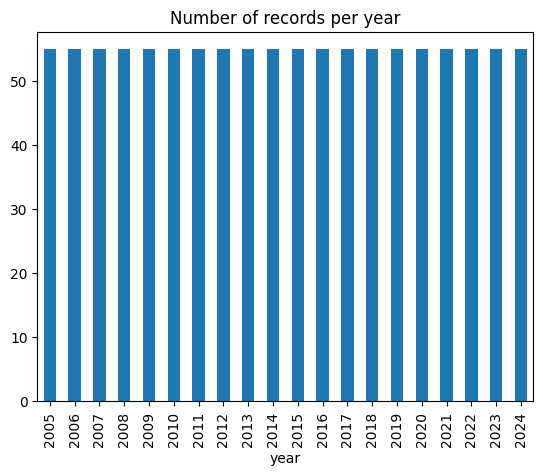

In [127]:
final_raw_df.groupby("year").size().plot(kind="bar")
plt.title("Number of records per year")
plt.show()

Based on the initial analysis, the dataset contains 1100 rows and 11 columns. The observations cover 55 countries over a period of 20 years, from 2005 to 2024. Each country has one observation per year, and each year includes data for all 55 countries.

The columns included in the dataset are as follow:
- country - the country analyzed in the project
- year - the year of observation
- house_price_to_income_index - an index showing the relationship between house prices and household - income, with 2015 used as the reference year
- housing_overburden - the percentage of the population living in households where total housing costs represent more than 40% of disposable household income
- house_price_index - an index showing how house prices changed compared to 2015, where 2015 equals 100
- rent_price_index - an index showing how rent prices changed compared to 2015, where 2015 equals 100
- population - the total number of people living in a given country
- living_with_parents - the percentage of people aged 18 to 34 living with their parents or  contributing/benefiting from the household income
- net_migration - the difference between immigration and emigration in a given country and year
- mean_childbirth_age - the average age of women at childbirth in a given country and year
- fertility_rate - the average number of children per woman in a given country and year

Regarding data types, the country column is stored as an object, the year column as an integer (int64), and all remaining indicator columns as floating-point values (float64).

### Data Quality Assessment

To assess the quality of the analyzed data, the number and percentage of missing values are calculated for each column. To better illustrate the results, a horizontal bar plots are presented (missing values per variable and country).

In [128]:
def show_missing_values(df):
    coverage = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean() * 100,
        "present_count": df.notna().sum()
    }).sort_values("missing_percent", ascending=False)

    return coverage

show_missing_values(final_raw_df)

,missing_count,missing_percent,present_count
house_price_to_income_index,560,50.91,540
house_price_index,548,49.82,552
housing_overburden,444,40.36,656
living_with_parents,434,39.45,666
rent_price_index,373,33.91,727
mean_childbirth_age,253,23.00,847
fertility_rate,253,23.00,847
population,126,11.45,974
net_migration,121,11.00,979
year,0,0.00,1100


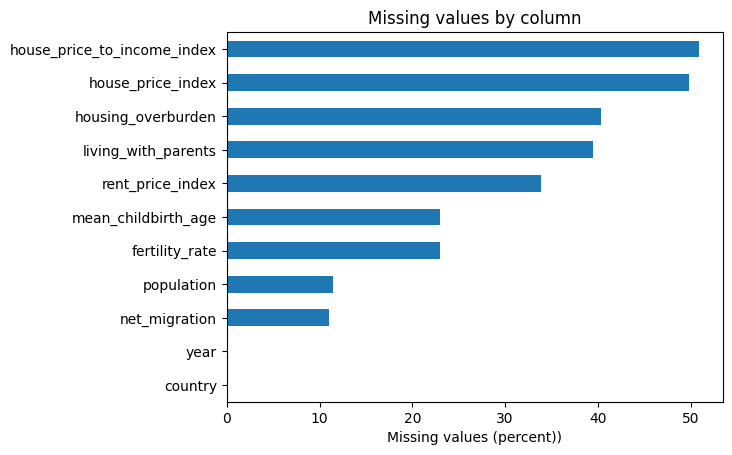

In [129]:
missing_percent = (final_raw_df.isna().mean() * 100).sort_values(ascending=True)

missing_percent.plot(kind="barh")
plt.xlabel("Missing values (percent))")
plt.title("Missing values by column")
plt.show()

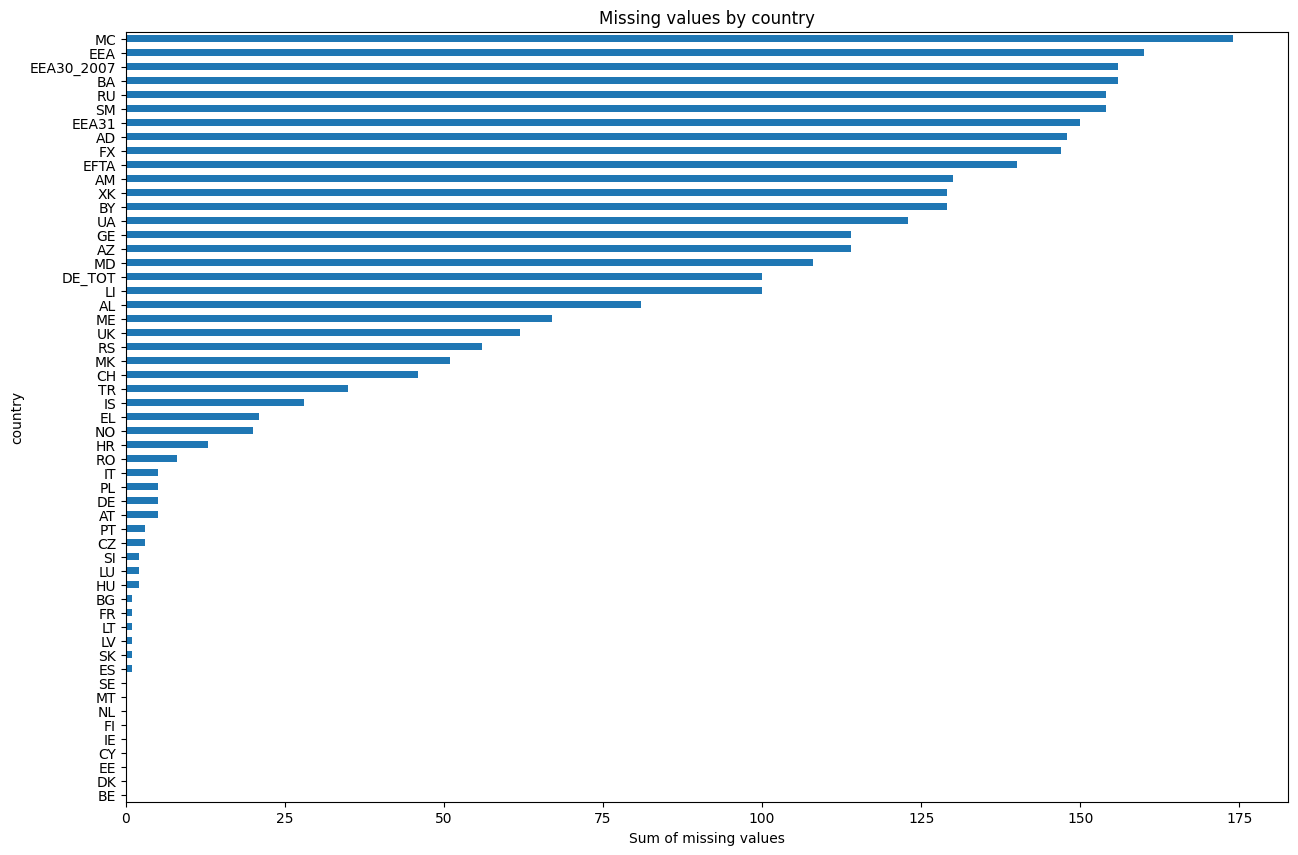

In [130]:

indicator_cols = [col for col in final_raw_df.columns if col not in ["country", "year"]]

missing_by_country = (
    final_raw_df.groupby("country")[indicator_cols]
    .apply(lambda x: x.isna().sum().sum())
    .sort_values()
)

missing_by_country.plot(kind="barh", figsize=(15,10))
plt.xlabel("Sum of missing values")
plt.title("Missing values by country")
plt.show()

Based on the table and the charts, it can be observed that several variables contain a substantial amount of missing data. This is especially visible for house_price_to_income_index, house_price_index, housing_overburden, living_with_parents, and rent_price_index, where the percentage of missing values exceeds 30%. This indicates that the dataset requires further cleaning. It also suggests that some countries may have very limited or no useful data for selected indicators and may need to be removed from the analysis. The second chart also reveals some uncommon country codes, such as EEA31, which may refer to groups of countries rather than individual locations. These entries need to be checked and handled appropriately before further analysis.

In [131]:
final_raw_df.duplicated().sum()

np.int64(0)

In [132]:
final_raw_df.duplicated(subset=["country", "year"]).sum()

np.int64(0)

No duplicates were observed in the analyzed data.

## Data Preparation

This section focuses on preparing the data for further analysis and for use in the final dataset for the Streamlit application. It includes handling suspicious entries, missing values, duplicates, and performing feature engineering.

In [133]:
final_df = final_raw_df.copy()

### Data cleaning

The first step was to check whether the dataset contained any unusual observations, such as negative index values or percentage values equal to 0.

In [134]:
final_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
0,AD,2005,NaN,NaN,NaN,76875.00,14.40,NaN,NaN,NaN,NaN
1,AD,2006,NaN,NaN,NaN,78549.00,26.20,NaN,30.30,1.24,NaN
2,AD,2007,NaN,NaN,NaN,81222.00,16.10,NaN,30.40,1.18,NaN
3,AD,2008,NaN,NaN,NaN,83137.00,8.50,NaN,30.50,1.25,NaN
4,AD,2009,NaN,NaN,NaN,84484.00,-11.50,NaN,31.10,1.19,NaN


In [135]:
numeric_columns = final_df.select_dtypes(include="number").columns.drop("year")
invalid = {}

for col in numeric_columns:
    invalid[col] = {
        "zero_values": (final_df[col] == 0).sum(),
        "negative_values": (final_df[col]<0).sum()
    }

to_investigate_df = pd.DataFrame(invalid).T
to_investigate_df

,zero_values,negative_values
house_price_to_income_index,0,0
housing_overburden,0,0
house_price_index,0,0
population,0,0
net_migration,26,276
living_with_parents,1,0
mean_childbirth_age,0,0
fertility_rate,0,0
rent_price_index,0,0


In [136]:
final_df[final_df["living_with_parents"] == 0]

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
1037,TR,2022,NaN,11.20,611.40,84680273.00,0.80,0.00,29.20,1.63,221.23


In [137]:
final_df.loc[final_df["living_with_parents"] == 0, "living_with_parents"] = pd.NA

During data verification, two indicators required additional attention. The net_migration column contained 26 zero values and 276 negative values. However, due to the nature of this indicator, these values were considered valid and left unchanged. In contrast, one observation in the living_with_parents column was equal to 0, which was considered suspicious and was therefore replaced with a missing value.

### Missing values

Before conducting trend and correlation analysis, missing values has to be handled appropriately. Since the dataset has a time-series structure, observations can not be removed randomly, and missing values should not remain unfilled. In order to obatined a proper datest the first step is to assess the overall percentage of missing values for each country across all columns.Countries with more than 50% missing values should be excluded from the dataset, as they did not provide enough information for further analysis.

In [138]:
columns_to_verify = []
for col in final_df.columns:
    if col not in ["country", "year"]:
        columns_to_verify.append(col)

missing_percent_by_country = final_df.groupby("country")[columns_to_verify].apply(
    lambda x: x.isna().mean().mean() * 100
)
countries = missing_percent_by_country[missing_percent_by_country < 50].index
final_df = final_df[final_df["country"].isin(countries)]

In [139]:
show_missing_values(final_df)

,missing_count,missing_percent,present_count
house_price_to_income_index,180,25.00,540
house_price_index,168,23.33,552
housing_overburden,65,9.03,655
living_with_parents,56,7.78,664
rent_price_index,23,3.19,697
mean_childbirth_age,12,1.67,708
fertility_rate,12,1.67,708
population,6,0.83,714
net_migration,5,0.69,715
year,0,0.00,720


Based on the table, it can be said that the number of missing values decreased significantly. However, house_price_to_income_index and house_price_index columns still contain more than 20% missing values. This may indicate that some countries have no available data for these variables. Since house_price_to_income_index is one of the key indicators in the analysis, this issue needs to be examined in more detail and such countries need to be removed.

In [140]:
missing_price_to_income= final_df.groupby("country")["house_price_to_income_index"].apply(
    lambda x: x.isna().sum()
)
pd.DataFrame(missing_price_to_income[missing_price_to_income == 20])

,house_price_to_income_index
country,
AL,20
CH,20
IS,20
ME,20
MK,20
NO,20
RS,20
TR,20
UK,20


In [141]:
countries_to_drop = missing_price_to_income[missing_price_to_income == 20].index
final_df = final_df[~final_df["country"].isin(countries_to_drop)].reset_index(drop=True)

In [142]:
missing_house_price_index= final_df.groupby("country")["house_price_index"].apply(
    lambda x: x.isna().sum()
)
pd.DataFrame(missing_house_price_index[missing_house_price_index == 20])

,house_price_index
country,
EL,20


In [143]:
countries_to_drop = missing_house_price_index[missing_house_price_index == 20].index
final_df = final_df[~final_df["country"].isin(countries_to_drop)].reset_index(drop=True)

In [144]:
final_df["country"].nunique()

26

The check showed that 10 countries had no available data in these two columns, and therefore they were removed from the dataset. As a result, the final dataset included 26 countries. This number was considered sufficient for the next stages of the project, as it is close to the number of European Union member states.

In [145]:
show_missing_values(final_df)

,missing_count,missing_percent,present_count
house_price_index,38,7.31,482
housing_overburden,14,2.69,506
living_with_parents,7,1.35,513
house_price_to_income_index,0,0.00,520
year,0,0.00,520
country,0,0.00,520
population,0,0.00,520
net_migration,0,0.00,520
mean_childbirth_age,0,0.00,520
fertility_rate,0,0.00,520


After removing countries with no values in selected columns and those exceeding the missing value threshold, the final step was to address the remaining gaps in the dataset. As shown in the table above, the highest precentage of missing values was found in the house_price_index column. However, this percentage was relatively low (7.31%) so the remaining missing values were filled using linear interpolation.

In [146]:
columns_to_interpolate = [
    "house_price_index",
    "housing_overburden",
    "living_with_parents"
]

final_df = final_df.sort_values(["country", "year"]).reset_index(drop=True)

for column in columns_to_interpolate:
    final_df[column] = (
        final_df
        .groupby("country")[column]
        .transform(lambda x: x.interpolate(method="linear", limit_direction="both"))
    )

In [147]:
show_missing_values(final_df)

,missing_count,missing_percent,present_count
country,0,0.00,520
year,0,0.00,520
house_price_to_income_index,0,0.00,520
housing_overburden,0,0.00,520
house_price_index,0,0.00,520
population,0,0.00,520
net_migration,0,0.00,520
living_with_parents,0,0.00,520
mean_childbirth_age,0,0.00,520
fertility_rate,0,0.00,520


### Duplicates

No duplicates were observed in the analyzed data.

### Feature Engineering

In order to enrich the  analysis and visualization, a new categorical variable was created based on the housing_overburden column. Its values ​​were divided into three groups: Low, Medium, and High, using quantile-based discretization. This allows to classify countries into one of these groups, see how they have changed their affiliation over the years and compare them to others according to the relative level of housing cost burden.

In [148]:
final_df["housing_overburden"].describe()

count   520.00
mean      8.29
std       4.25
min       1.10
25%       5.00
50%       7.70
75%      10.30
max      24.20
Name: housing_overburden, dtype: float64

In [149]:
final_df["housing_burden_category"] = pd.qcut(
    final_df["housing_overburden"],
    q=3,
    labels=["Low", "Medium", "High"]
)

final_df[["country", "year", "housing_burden_category"]]

,country,year,housing_burden_category
0,AT,2005,Low
1,AT,2006,Low
2,AT,2007,Low
3,AT,2008,Medium
4,AT,2009,Medium
...,...,...,...
515,SK,2020,Low
516,SK,2021,Medium
517,SK,2022,Low
518,SK,2023,Medium


## Exploratory Data Analysis

The goal of this section is to conduct an exploratory data analysis of the prepared and cleaned dataset. This step helps to better understand the data, identify hidden patterns, examine relationships between housing and selected social variables, and analyze trends over time. It also includes exploring the distribution of key indicators, comparing results across countries, and detecting potential outliers. Overall, this analysis provides a stronger understanding of the problem and supports the development of a more meaningful final Streamlit application.

In [150]:
final_df.shape

(520, 12)

In [151]:
indicator_cols = [col for col in final_df.columns if col not in ["country", "year", "housing_burden_category"]]

In [152]:
final_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index,housing_burden_category
0,AT,2005,85.87,4.60,77.32,8201359.00,6.10,44.50,29.00,1.41,72.15,Low
1,AT,2006,85.37,5.00,77.32,8254298.00,3.00,45.80,29.20,1.41,73.76,Low
2,AT,2007,84.89,5.40,77.32,8282984.00,2.80,47.00,29.40,1.38,75.21,Low
3,AT,2008,83.25,8.50,77.32,8307989.00,2.90,46.00,29.50,1.42,76.16,Medium
4,AT,2009,83.19,8.00,77.32,8335003.00,2.10,47.40,29.70,1.39,79.74,Medium


In [153]:
print(f"Final set of countries: {final_df["country"].nunique()}")
print(f"Years: {final_df["year"].min()} - {final_df["year"].max()}")
print(f"Rows: {len(final_df)}")

Final set of countries: 26
Years: 2005 - 2024
Rows: 520


In [154]:
final_df.describe()

,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index
count,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00
mean,2014.50,108.51,8.29,117.35,16609375.82,3.60,49.88,30.15,1.53,100.83
std,5.77,20.03,4.25,33.32,21998031.54,7.60,14.87,1.33,0.20,19.17
min,2005.00,55.88,1.10,52.04,402668.00,-25.20,15.50,25.90,1.01,38.64
25%,2009.75,98.28,5.00,97.19,2942557.50,-0.10,41.75,29.40,1.38,90.85
50%,2014.50,104.20,7.70,107.52,7944966.00,2.60,52.80,30.35,1.50,100.00
75%,2019.25,113.98,10.30,131.28,16847148.25,5.93,60.60,31.10,1.66,108.45
max,2024.00,263.14,24.20,309.86,83456045.00,42.10,78.20,33.20,2.06,187.10


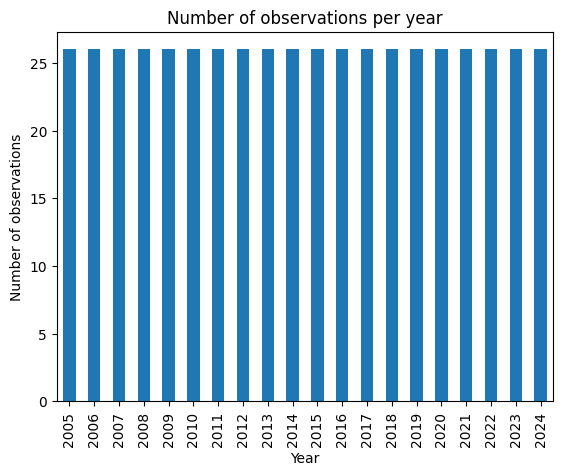

In [155]:
final_df.groupby("year").size().plot(kind="bar")
plt.title("Number of observations per year")
plt.xlabel("Year")
plt.ylabel("Number of observations")
plt.show()

### Univariate Analysis (Distributions)

The histogram chart below shows the distributions of all numerical variables in the dataset. Most of them do not follow a normal distribution, as skewness and outliers can be observed. A good example is population, which is strongly right-skewed because most countries have relatively small populations with some exceptions. The house_price_to_income_index, rent_price_index, and house_price_index are concentrated around the reference value of 100, which is expected because these indicators are index-based. In the case of social indicators, the distributions of fertility_rate and mean_childbirth_age are more regular, although some variation between observations is still visible. For net_migration, potential outliers can be observed, which suggests large differences in migration patterns between countries and years. Overall, the distributions indicate that further analysis should take outliers into account and consider differences between countries across multiple dimensions.

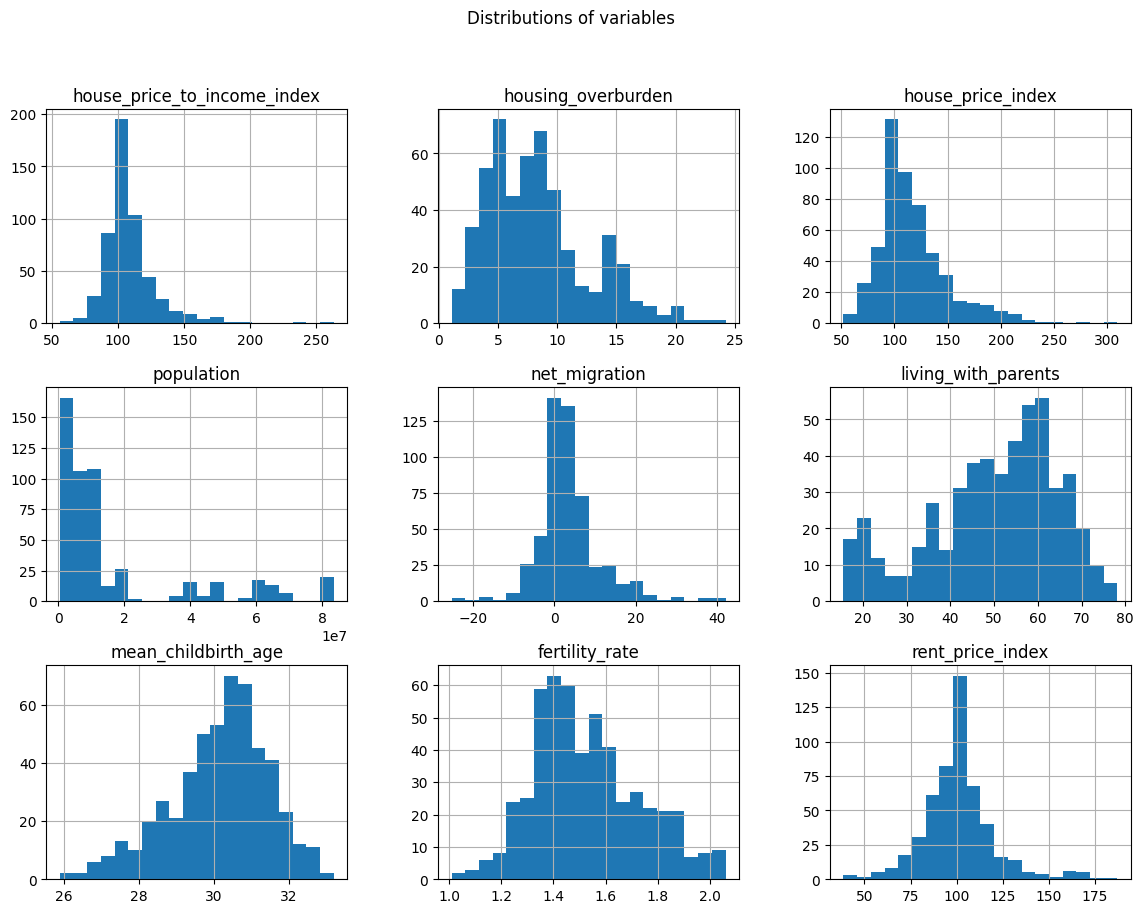

In [156]:
final_df[indicator_cols].hist(bins=20, figsize=(14, 10))
plt.suptitle("Distributions of variables")
plt.show()

 ### Trends Analysis

Trend analysis of the selected variables allows us not only to examine how their values changed between 2005 and 2024, but also to identify differences and similarities across European countries.

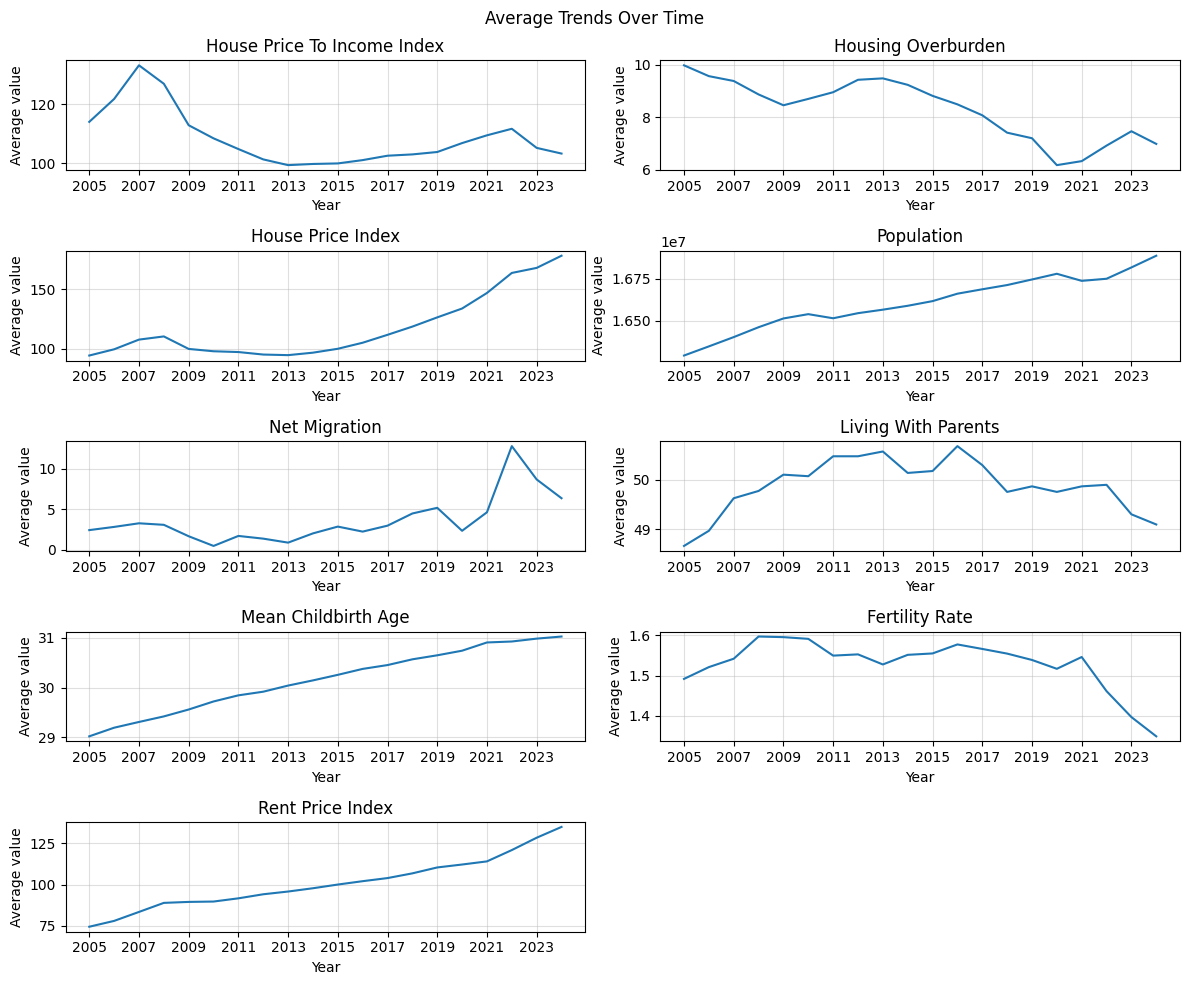

In [157]:
yearly_avg = final_df.groupby("year")[indicator_cols].mean()
fig, axes  = plt.subplots(5,2, figsize=(12,10))
axes = axes.flatten()

for i, column in enumerate(indicator_cols):
    ax = axes[i]

    ax.plot(
        yearly_avg.index.astype(int),
        yearly_avg[column],
    )
    
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Year")
    ax.set_xticks(yearly_avg.index[::2])
    ax.set_ylabel("Average value")
    ax.grid(alpha=0.4)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.suptitle("Average Trends Over Time")
plt.tight_layout()
plt.show()

The line plots above show the overall mean trend over time for each variable in the analyzed dataset. Based on them, several interesting patterns can be observed. Among housing-related indicators, both house_price_index and rent_price_index show a steady increase over time. However, in the case of rent_price_index, the average values before 2015 were much below the reference value of 100, while house_price_index stayed close to or even above this level. The house_price_to_income_index shows a less stable trend - it reaches a peak around 2007 and then decreases instead of continuously increasing as happened in rent/house prices. After 2015 we can see a slight increase. This may suggest that income growth partly balanced the increase in housing prices in later years. Housing_overburden generally decreases over time, which may suggest a lower average housing cost burden in recent years.

When it comes to social indicators, mean_childbirth_age increases steadily, while fertility_rate declines significantly after 2021. Net_migration reaches its peak in 2022, which may be related to the situation in Europe at that time, including the war in Ukraine. The average population also shows a gradual upward trend. The percentage of people aged 18-34 living with their parents increased after 2005, but started to gradually decline around 2016.

Overall, the charts indicate clear long-term changes in both housing conditions and social indicators.

In [158]:
main_variables_trends = (
    final_df.groupby("year")[
        ["house_price_index",
         "rent_price_index",
         "house_price_to_income_index"]
    ]
).mean()

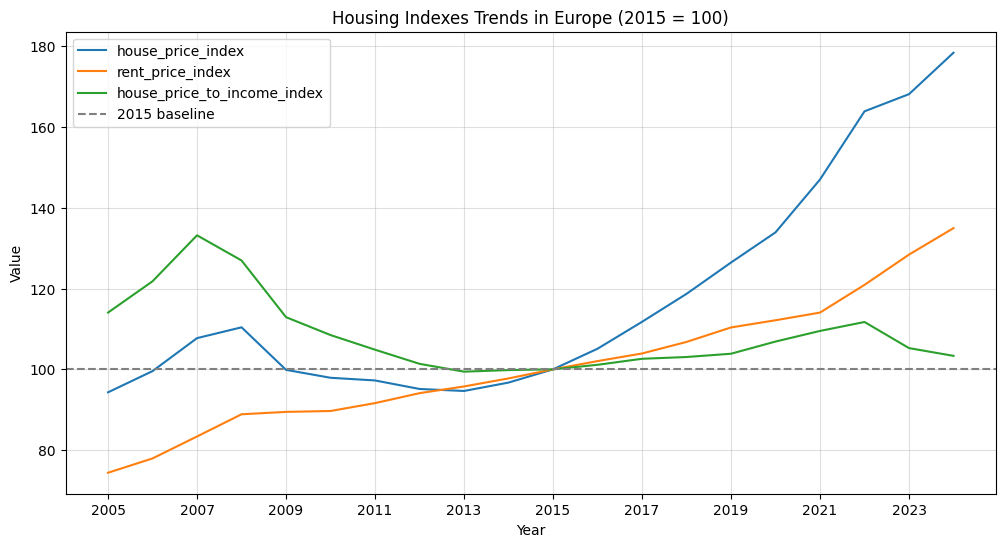

In [159]:
plt.figure(figsize=(12,6))
for column in main_variables_trends.columns:
    plt.plot(main_variables_trends.index, main_variables_trends[column], label=column)
plt.axhline(100, color="gray", linestyle="--", label="2015 baseline")
plt.title("Housing Indexes Trends in Europe (2015 = 100)")
plt.xlabel("Year")
plt.xticks(main_variables_trends.index[::2])
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.4)

plt.show()

The plot above shows the mean values of each index variable across all analyzed countries. In recent years (after 2015), both house and rent prices increased compared to the baseline. The strongest growth can be observed for house_price_index, which reached almost 180 in 2024, meaning an increase of about 80% compared to 2015. The rent_price_index also increased steadily, although at a slower pace, reaching around 135-140 in 2024. 

Interestingly, the house_price_to_income_index stayed above the baseline for most of the analyzed period and fell slightly below 100 only around 2013-2014. It reached its peak around 2007 and then declined until 2015, which may suggest that income growth partly balanced housing price increases during that period. After 2015, the index value increases again, but after 2022 it started to decrease, indicating that house prices grew less strongly relative to income, despite the continued increase in house prices.

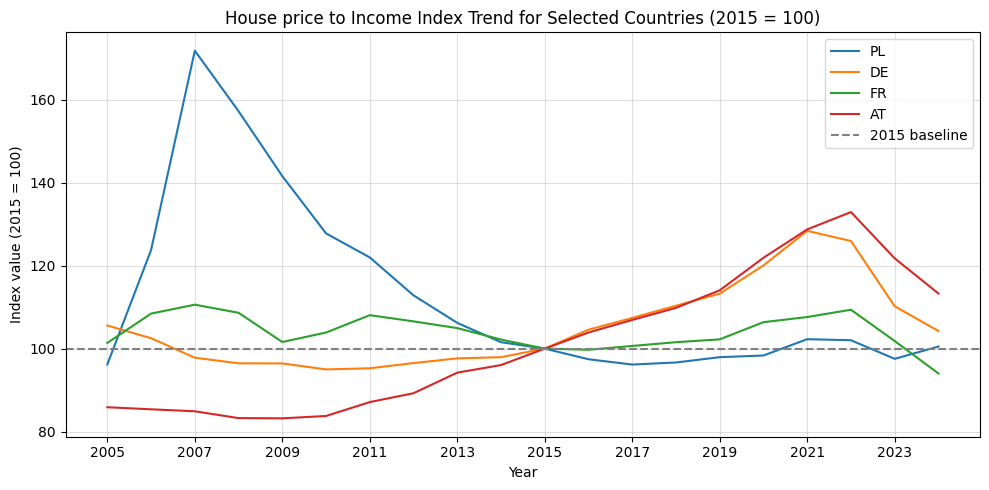

In [160]:
selected_countries = ["PL", "DE", "FR", "AT"]

plt.figure(figsize=(10,5))
for country in selected_countries:
    country_data = final_df.loc[final_df["country"] == country]
    plt.plot(country_data["year"], country_data["house_price_to_income_index"], label=country)
    
plt.axhline(100, color="gray", linestyle="--", label="2015 baseline")
plt.xlabel("Year")
plt.xticks(sorted(final_df["year"].unique())[::2])
plt.ylabel("Index value (2015 = 100)")
plt.title("House price to Income Index Trend for Selected Countries (2015 = 100)")
plt.grid(alpha=0.4)
plt.legend()
plt.tight_layout()


plt.show()

The line chart shows how the house_price_to_income_index changed over time for selected countries: Poland, Germany, France, and Austria. Germany and Austria follow a similar pattern, with values below the baseline before 2015, except for Germany around 2005-2006, and a clear increase after 2015, reaching their peaks around 2021-2022. In the case of France, the trend is less clear. The values remain above the baseline for most of the period, but a slightly stronger decrease can be observed after 2022. Poland shows the most unusual pattern - the index reaches a very high peak in 2007, which may be related to the economic situation at that time such as the pre-2008 housing market boom, and then decreases significantly. In later years, the values remain close to the 2015 reference level.

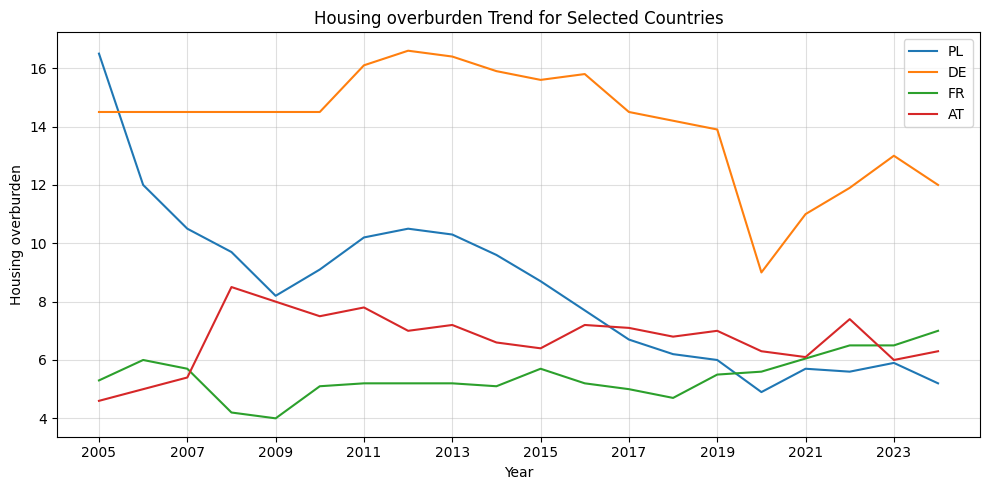

In [161]:
plt.figure(figsize=(10,5))
for country in selected_countries:
    country_data = final_df.loc[final_df["country"] == country]
    plt.plot(country_data["year"], country_data["housing_overburden"], label=country)
    
plt.xlabel("Year")
plt.xticks(sorted(final_df["year"].unique())[::2])
plt.ylabel("Housing overburden")
plt.title("Housing overburden Trend for Selected Countries")
plt.grid(alpha=0.4)
plt.legend()
plt.tight_layout()


plt.show()

The line plot shows how housing overburden changed over time for selected countries: Poland, Germany, France, and Austria. In Poland, the peak in 2005 is clearly visible, indicating that this was the year when the highest share of people spent more than 40% of their income on housing costs. After that, a significant decrease can be observed. Since Poland has developed quickly over the past 30 years, the lower housing burden in later years seems reasonable. Germany has the highest values among the selected countries for most of the period, although a strong decrease is visible around 2019-2020, which may be related to the COVID-19 pandemic.Trends for France and Austria remain much lower and relatively stable, with only moderate fluctuations. Overall, it can be concluded that housing cost pressure decreased in Poland and Germany, while it stayed more stable in France and Austria.

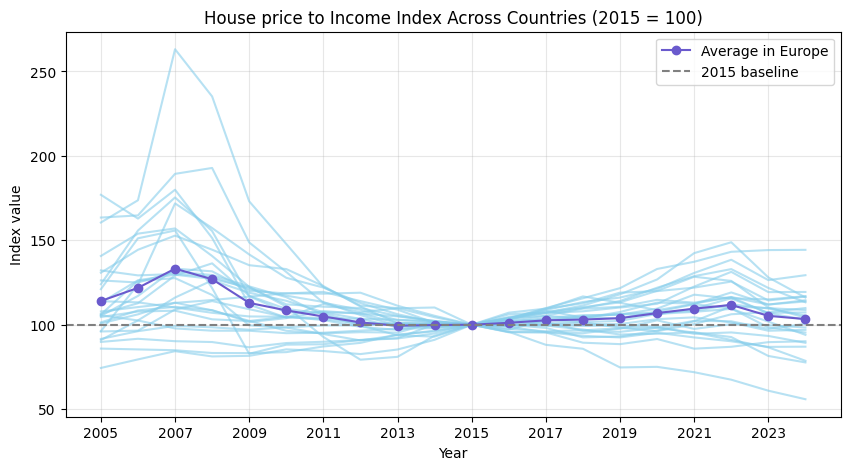

In [162]:
main_column = "house_price_to_income_index"
yearly_avg= final_df.groupby("year")[main_column].mean()

plt.figure(figsize=(10, 5))

for country in final_df["country"].unique():
    country_data = final_df.loc[final_df["country"] == country]
    plt.plot(
        country_data["year"],
        country_data[main_column],
        color="skyblue",
        alpha=0.6
    )

plt.plot(
    yearly_avg.index,
    yearly_avg,
    color= "slateblue",
    marker = "o",
    label="Average in Europe"
)

plt.axhline(100, color="gray", linestyle="--", label="2015 baseline")
plt.title("House price to Income Index Across Countries (2015 = 100)")
plt.xlabel("Year")
plt.ylabel("Index value")
plt.xticks(sorted(final_df["year"].unique())[::2])
plt.grid(alpha=0.3)
plt.legend()

plt.show()

The lineplot shows the trend for house_price_to_income_index variable across all 26 countries, with the European average highlighted in purple. The strongest differences between countries are visible around 2007, when some of them reached very high values. After 2015, the trend lines are more concentrated around the baseline, although some differences are still visible The European average stays close to 100 for most of the period. Only two slight increases can be observed in 2007 and 2022. The relationship between house prices and income remained relatively stable in recent years, despite stronger changes in some individual countries.

In [163]:
def create_change(df, main_column):    
    base_year = 2015
    latest_year = 2024

    base_data = df[df["year"] == base_year][["country", main_column]]
    latest_data = df[df["year"] == latest_year][["country", main_column]]
    change_df = base_data.merge(latest_data, on= "country", suffixes=("_2015", "_2024"))
    change_df["value_change"] = change_df[f"{main_column}_{latest_year}"] - change_df[f"{main_column}_{base_year}"]

    change_df_sorted = change_df.sort_values("value_change")
    return change_df_sorted

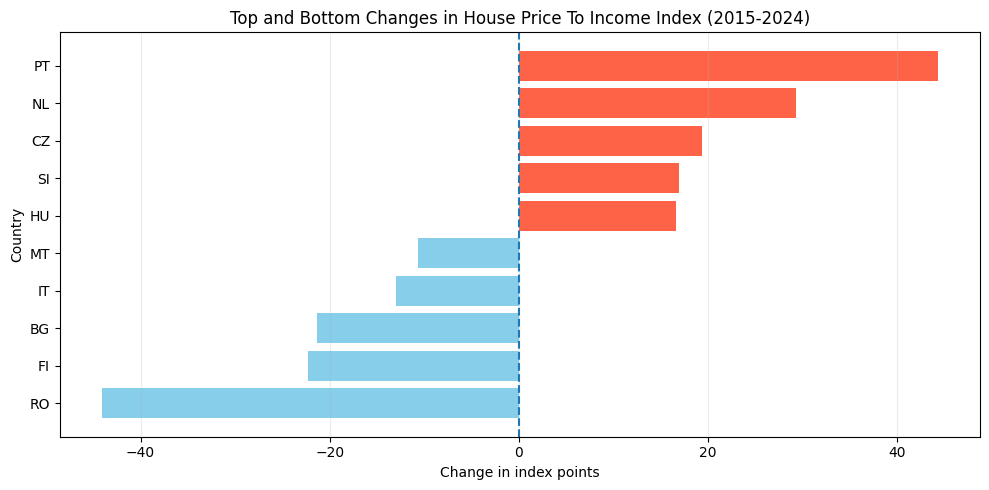

In [164]:
main_column = "house_price_to_income_index"
change_df_sorted = create_change(final_df, main_column)
bottom = change_df_sorted.head(5)
top= change_df_sorted.tail(5)
top_bottom = pd.concat([bottom, top])

colors =[]
for value in top_bottom["value_change"]:
    if value > 0:
        colors.append("tomato")
    else:
        colors.append("skyblue")


plt.figure(figsize=(10, 5))
plt.barh(top_bottom["country"], top_bottom["value_change"], color=colors)
plt.axvline(0, linestyle="--")
plt.title(f"Top and Bottom Changes in {main_column.replace("_", " ").title()} (2015-2024)")
plt.xlabel("Change in index points")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

The plot above presents countries with the largest increases and decreases in house_price_to_income_index between 2015 and 2024. Portugal reached the strongest increase, followed by the Netherlands, Czechia, Slovenia, and Hungary. In other words, this means that in these countries house prices grew faster relative to income compared to the baseline year 2015. On the other hand, Romania, Finland, Bulgaria, Italy, and Malta recorded the largest decreases.

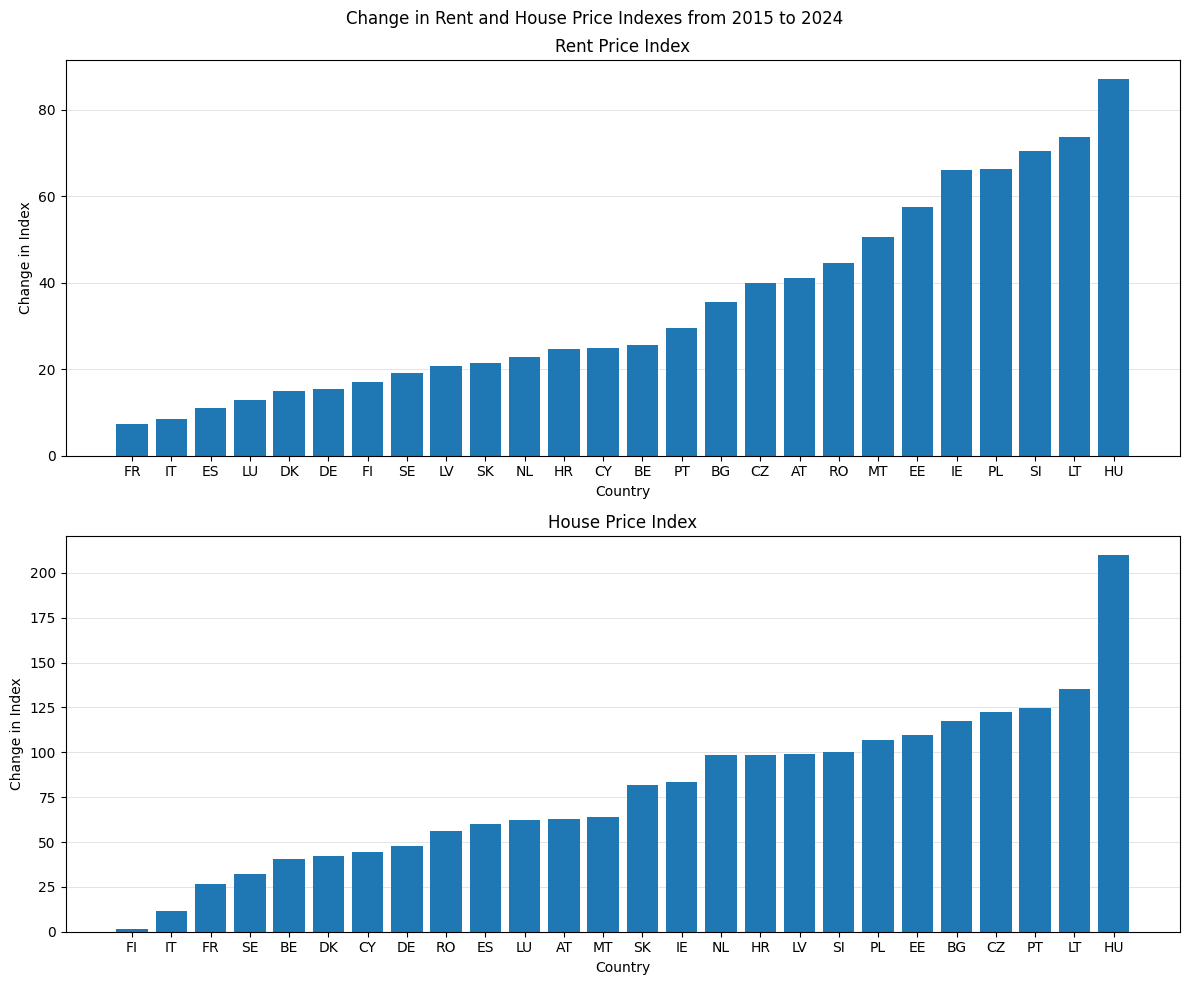

In [165]:
rent_column = "rent_price_index"
rent_change = create_change(final_df, rent_column)

house_column = "house_price_index"
house_change = create_change(final_df, house_column)

fig, axes  = plt.subplots(2,1, figsize=(12,10))
ax = axes.flatten()
ax[0].bar(
    rent_change["country"],
    rent_change["value_change"]
)

ax[0].set_title(rent_column.replace("_", " ").title())
ax[0].set_xlabel("Country")
ax[0].set_ylabel("Change in Index")
ax[0].grid(axis="y", linewidth=0.6, alpha=0.4)
ax[0].set_axisbelow(True)

ax[1].bar(
    house_change["country"],
    house_change["value_change"]
)

ax[1].set_title(house_column.replace("_", " ").title())
ax[1].set_xlabel("Country")
ax[1].set_ylabel("Change in Index")
ax[1].grid(axis="y", linewidth=0.6, alpha=0.4)
ax[1].set_axisbelow(True)

plt.suptitle("Change in Rent and House Price Indexes from 2015 to 2024")
plt.tight_layout()
plt.show()


The bar plots above show how rent_price_index and house_price_index changed between 2015 and 2024 for each country. The change was calculated by subtracting the 2015 index value from the 2024 value, so higher bars indicate stronger price growth. Based on both charts, all countries recorded positive changes, which means that both rent and house prices increased compared to 2015.

In both cases, the largest increases were observed in Hungary and Lithuania. Hungary stands out especially in the house_price_index, where the growth was much higher than in the other countries. The remaining country rankings differ between the two plots to some extent. For example, France experienced one of the lowest rental price increases, but its house price growth is closer to the middle of the rankings. Overall, it can be concluded that in most of the countries analyzed, purchase prices of apartments grew faster than rental prices between 2015 and 2024.

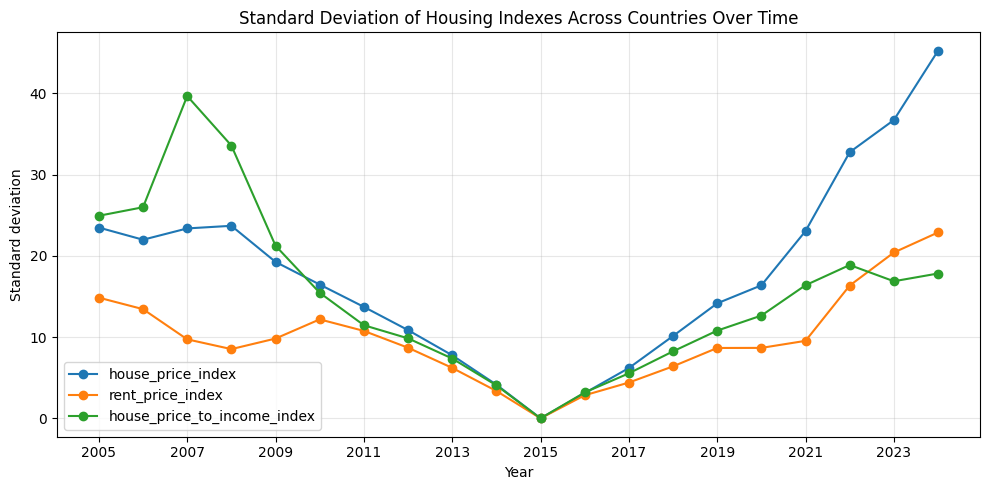

In [166]:
main_variables = ["house_price_index", "rent_price_index", "house_price_to_income_index"]
std_per_year = final_df.groupby("year")[main_variables].std()

plt.figure(figsize=(10, 5))
for column in main_variables:
    plt.plot(std_per_year.index, std_per_year[column], marker="o", label=column)


plt.title("Standard Deviation of Housing Indexes Across Countries Over Time")
plt.xlabel("Year")
plt.ylabel("Standard deviation")
plt.xticks(sorted(final_df["year"].unique())[::2])

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

The graph shows how the variation across countries in housing-related indicators has changed over time. In 2015, the standard deviation was 0, as that was the reference year. After 2015, standard deviation increases again, particularly for the house_price_index, meaning that house prices grew at very different rates across countries. Before 2015, the largest variations were seen for the house_price_to_income_index, especially around 2007.

### Correlation Analysis

In [167]:
corr_cols =  [col for col in final_raw_df.columns if col not in ["country", "year"]]

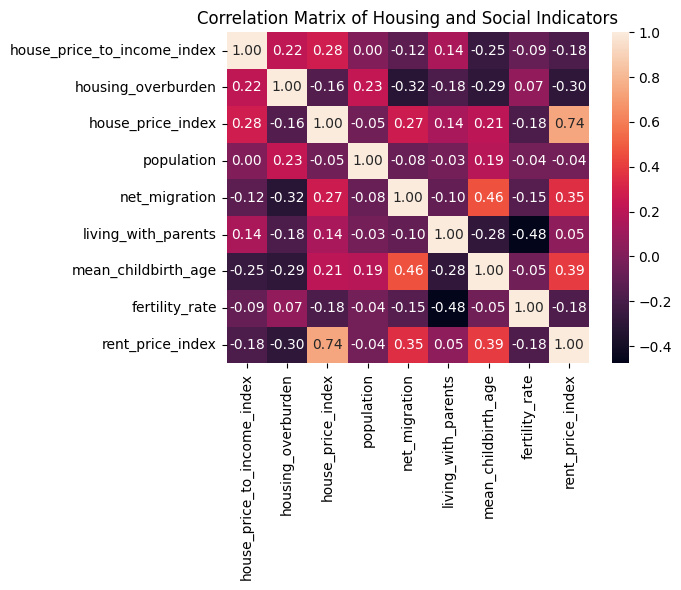

In [168]:
corr = final_df[corr_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"    
)

plt.title("Correlation Matrix of Housing and Social Indicators")
plt.tight_layout()
plt.show()

The correlation matrix above presents the relationships between all analyzed variables. The strongest positive correlation is observed between house_price_index and rent_price_index (0.74), meaning that countries with increasing house prices also tend to have increasing rent prices. Apart from that we can't see any other strong correlation. Moderate positive correlation is visible between net_migration and mean_childbirth_age (0.46) and rent_price_index and mean_childbirth_age (0.39). The latter means that there can be a dependence between the time of family formation and the increace in rental price. The strongest negative correlation is between living_with_parents and fertility_rate (-0.48), which seems reasonable. In general, the observed relationships are rather weak or moderate. The scatterplot matrix below illustrates the described correlations.

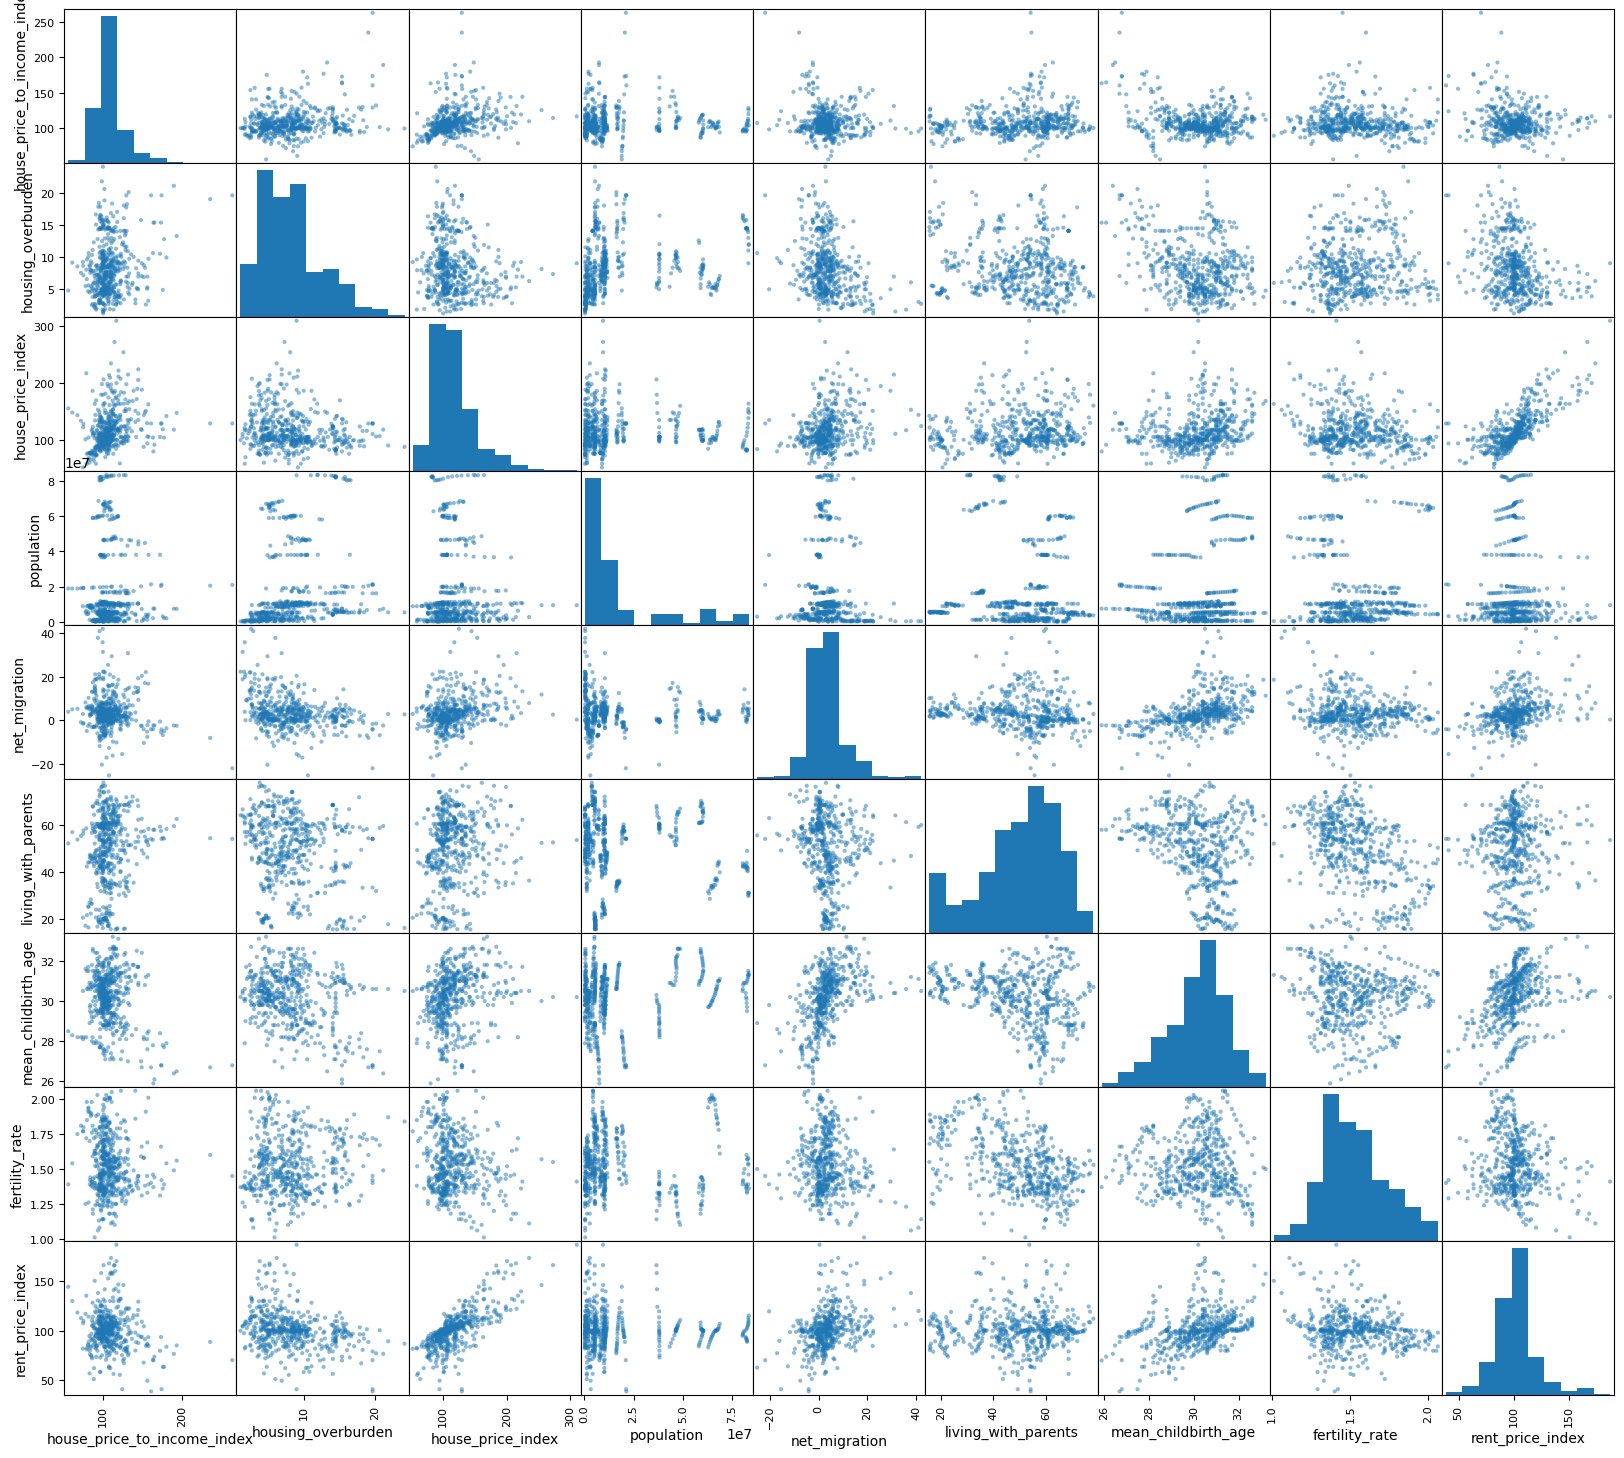

In [169]:
pd.plotting.scatter_matrix(final_df[indicator_cols], figsize=(20, 18))
plt.show()

The code below allows us to look at the highest absolute correlations and select them for further, more in-depth analysis.

In [170]:
corr_ranking = (
    corr
    .stack()
    .reset_index()
)
corr_ranking.columns = ["variable_1","variable_2","correlation"]
corr_ranking = corr_ranking[corr_ranking["variable_1"] != corr_ranking["variable_2"]]

corr_ranking["variables_pair"] = corr_ranking.apply(
    lambda row: tuple(sorted([row["variable_1"], row["variable_2"]])), axis=1)
corr_ranking = corr_ranking.drop_duplicates("variables_pair")

corr_ranking = corr_ranking.sort_values(by="correlation", key=lambda x: abs(x), ascending=False)

corr_ranking = corr_ranking[["variable_1", "variable_2", "correlation"]]
corr_ranking.head(10)

,variable_1,variable_2,correlation
26,house_price_index,rent_price_index,0.74
52,living_with_parents,fertility_rate,-0.48
42,net_migration,mean_childbirth_age,0.46
62,mean_childbirth_age,rent_price_index,0.39
44,net_migration,rent_price_index,0.35
13,housing_overburden,net_migration,-0.32
17,housing_overburden,rent_price_index,-0.30
15,housing_overburden,mean_childbirth_age,-0.29
51,living_with_parents,mean_childbirth_age,-0.28
2,house_price_to_income_index,house_price_index,0.28


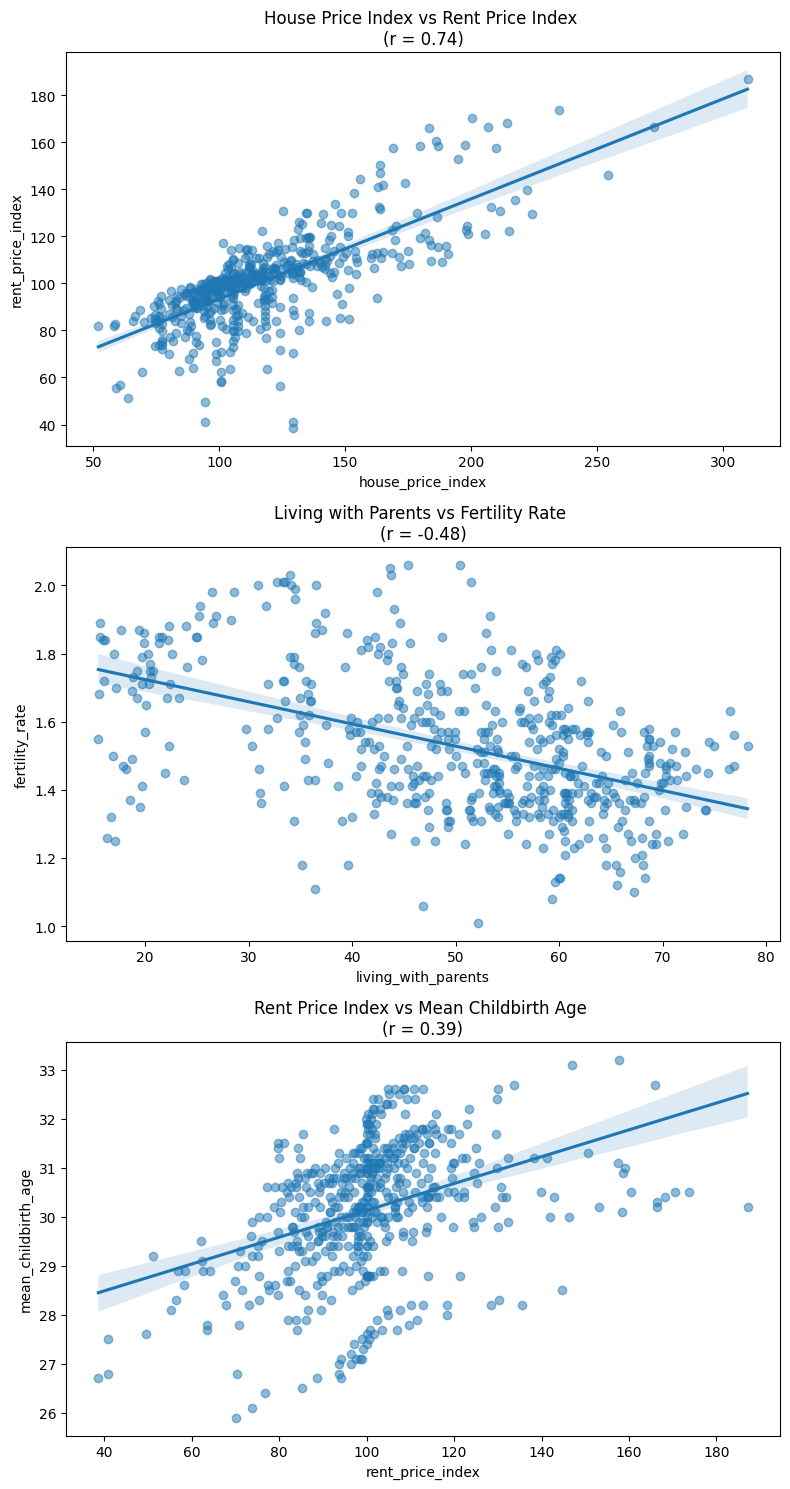

In [171]:
fig, axes = plt.subplots(3, 1, figsize=(8, 15))

sns.regplot(
    data=final_df,
    x="house_price_index",
    y="rent_price_index",
    scatter_kws={"alpha":0.5},
    ax=axes[0]
)
axes[0].set_title("House Price Index vs Rent Price Index \n(r = 0.74)")

sns.regplot(
    data=final_df,
    x="living_with_parents",
    y="fertility_rate",
    scatter_kws={"alpha":0.5},
    ax=axes[1]
)

axes[1].set_title("Living with Parents vs Fertility Rate \n(r = -0.48)")

sns.regplot(
    data=final_df,
    x="rent_price_index",
    y="mean_childbirth_age",
    scatter_kws={"alpha": 0.5},
    ax=axes[2]
)
axes[2].set_title("Rent Price Index vs Mean Childbirth Age \n(r = 0.39)")

plt.tight_layout()
plt.show()

For a more detailed exploration, three relationships with the highest absolute correlation values were selected and visualized using scatterplots. The first plot shows the relationship between two housing indexes: house_price_index and rent_price_index. This relationship presents the clearest pattern, and the positive trend confirms that higher house prices are usually associated with higher rent prices. Additionally, most observations are concentrated around the reference value of 100.

The second plot illustrates the negative correlation between living_with_parents and fertility_rate. Based on this, it can be concluded that countries or years with a higher share of young adults living with their parents tend to have lower fertility rates. However, the relationship is not very strong, so this conclusion should be treated with caution.

The third graph shows a moderate positive relationship between rent_price_index and mean_childbirth_age, which may indicate that higher rental prices are associated with a higher average age at childbirth.

In [172]:
pearson_corr = final_df[corr_cols].corr(method="pearson")
spearman_corr = final_df[corr_cols].corr(method="spearman")

comparison = pd.DataFrame({
    "pearson": [
        pearson_corr.loc["house_price_index", "rent_price_index"],
        pearson_corr.loc["living_with_parents", "fertility_rate"],
        pearson_corr.loc["rent_price_index", "mean_childbirth_age"]
    ],
    "spearman": [
        spearman_corr.loc["house_price_index", "rent_price_index"],
        spearman_corr.loc["living_with_parents", "fertility_rate"],
        spearman_corr.loc["rent_price_index", "mean_childbirth_age"]
    ]
}, index=[
    "house_price_index vs rent_price_index",
    "living_with_parents vs fertility_rate",
    "rent_price_index vs mean_childbirth_age"
])

comparison

,pearson,spearman
house_price_index vs rent_price_index,0.74,0.72
living_with_parents vs fertility_rate,-0.48,-0.46
rent_price_index vs mean_childbirth_age,0.39,0.44


The correlation analysis raised the question of whether the absence of strong relationships could be influenced by the presence of outliers. To investigate this, Pearson and Spearman correlation coefficients were compared. The results were highly consistent across all analyzed variable pairs. Since Spearman correlation is less sensitive to extreme values, the similarity between the two measures suggests that the observed relationships are not primarily driven by outliers. Consequently, the identified outliers were retained in the dataset and treated as meaningful observations rather than data quality issues.

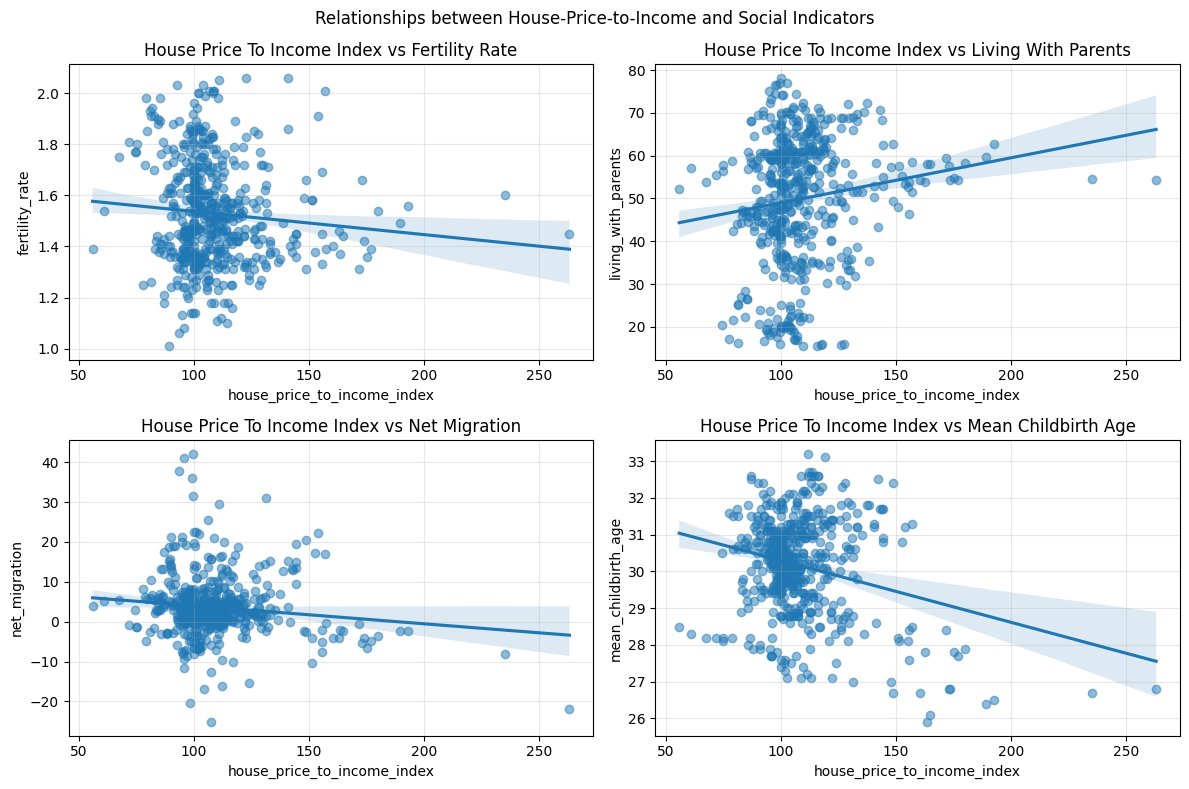

In [173]:
pairs_for_scatterplot = [
    ("house_price_to_income_index", "fertility_rate"),
    ("house_price_to_income_index", "living_with_parents"),
    ("house_price_to_income_index", "net_migration"),
    ("house_price_to_income_index", "mean_childbirth_age")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, (x, y) in enumerate(pairs_for_scatterplot):
    ax = axes[i]
    
    sns.regplot(data=final_df, x=x, y=y, ax=ax, scatter_kws={"alpha": 0.5})
    
    ax.set_title(f"{x.replace("_", " ").title()} vs {y.replace("_", " ").title()}")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.grid(alpha=0.3)

plt.suptitle("Relationships between House-Price-to-Income and Social Indicators")
plt.tight_layout()
plt.show()

The scatter plots show that the relationships between house_price_to_income_index and social indicators are weak, as most observations are concentrated around the reference value.

### Outlier Analysis

The final step of the EDA is to examine possible outliers. For this purpose, boxplots were created and the number of outliers was calculated for each numerical column using the IQR method. The population variable was excluded from this step because its values naturally differ greatly between countries, and extreme values reflect real differences in country size rather than data quality issues.

In [174]:
for_boxplots = [col for col in indicator_cols if col != "population"]
len(for_boxplots)


8

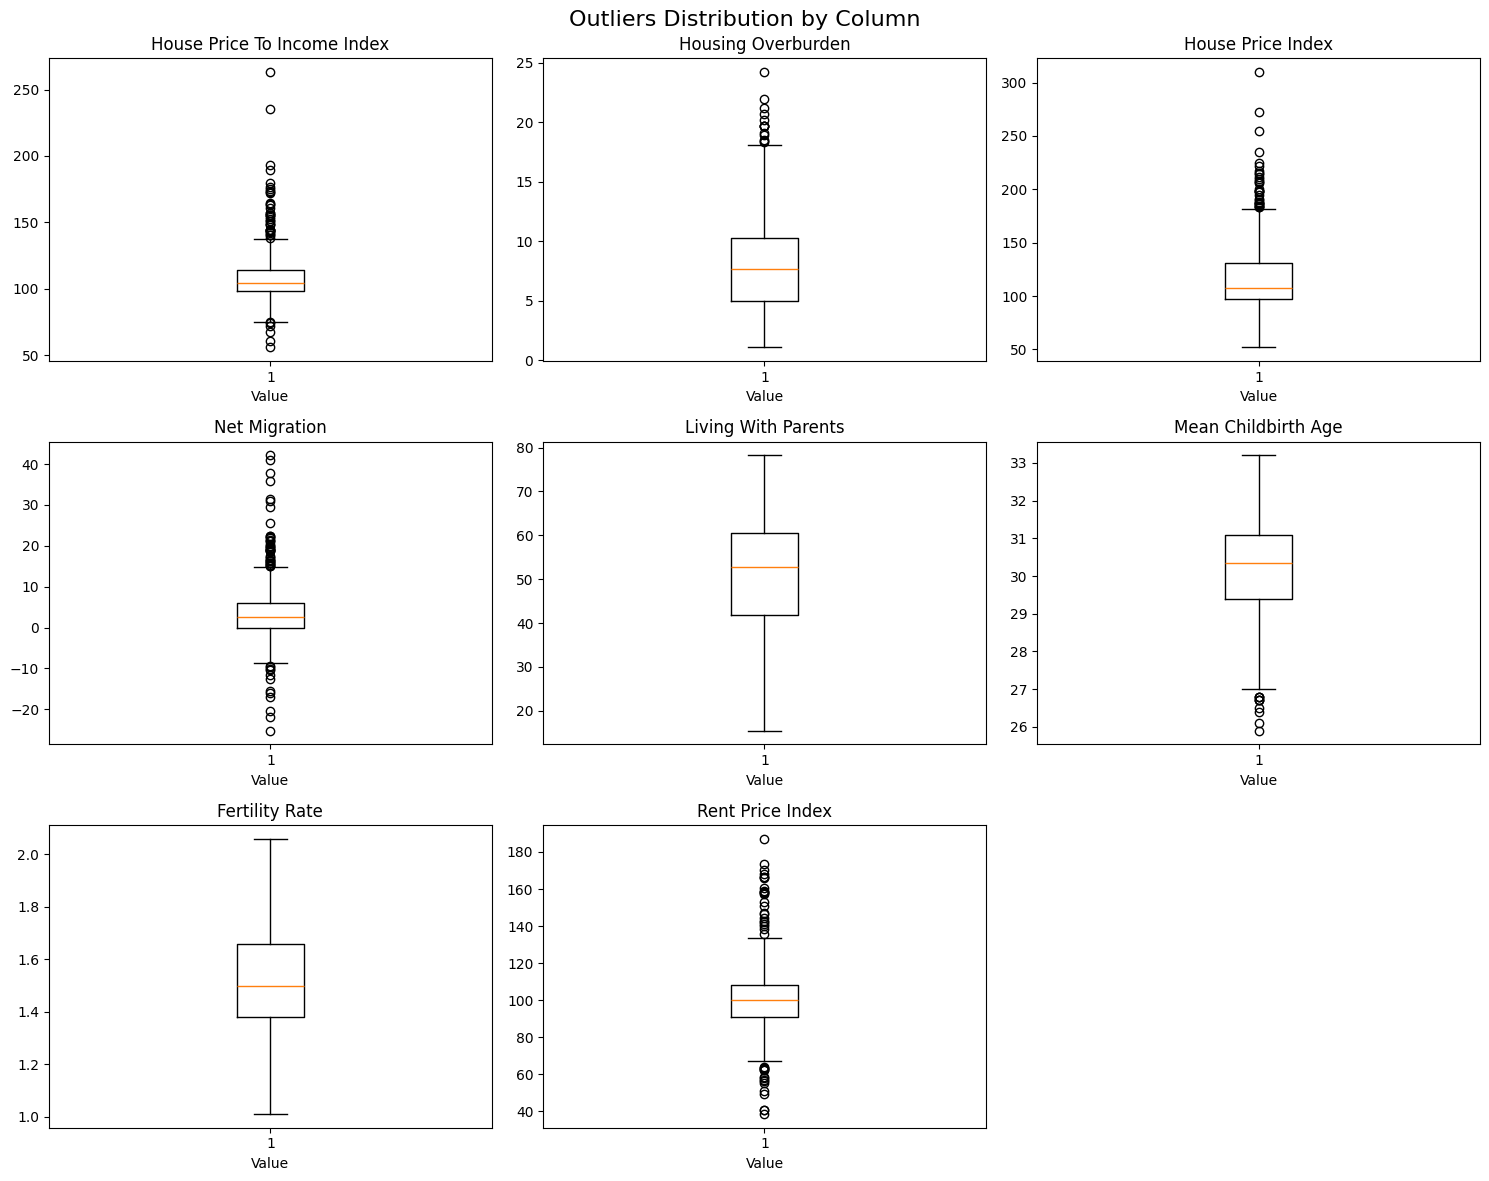

In [175]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, column in enumerate(for_boxplots):
    ax = axes[i]
    ax.boxplot(final_df[column].dropna())
    
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Value")
   

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.suptitle("Outliers Distribution by Column", fontsize=16)
plt.tight_layout()
plt.show()

The boxplots above show an interesting pattern - most outliers appear in the net_migration column and in housing-related indicators such as house_price_to_income_index, house_price_index, and rent_price_index. Most housing-related outliers are located above the upper quartile range, which means that some countries or years experienced much stronger increases in prices. This may be related to economic or global events, such as financial crises, war, or other external factors. Similarly, outliers in net_migration reflect large differences in migration patterns across countries and years. Overall, the outliers seem to represent real country-level differences rather than clear data errors.

In [176]:
outliers_summary = []
for column in for_boxplots:
    Q1 = final_df[column].quantile(0.25)
    Q3 = final_df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((final_df[column] < lower) | (final_df[column] > upper)).sum()
    
    outliers_summary.append({
        "variable": column,
        "outlier_count": outliers,
        "outlier_percent": outliers / len(final_df) * 100
    })

outliers_df = pd.DataFrame(outliers_summary).sort_values("outlier_count", ascending=False)
outliers_df

,variable,outlier_count,outlier_percent
3,net_migration,52,10.00
0,house_price_to_income_index,42,8.08
7,rent_price_index,40,7.69
2,house_price_index,31,5.96
1,housing_overburden,14,2.69
5,mean_childbirth_age,10,1.92
4,living_with_parents,0,0.00
6,fertility_rate,0,0.00


The table above presents the number and percentage of outliers for each variable. Due to the nature of the problem, we decided not to remove or modify them, as they reflect the relative global situation. To verify the validity of our approach, we additionally checked how the outliers compare to the national average for the first two variables on the list and which specific countries they refer to. For example, in the case of migration, two countries appear frequently: Malta and Luxembourg, which indicates a general migration trend in these countries in specific years, such as increasing popularity.

In [177]:
def get_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (df[column] < lower) | (df[column] > upper)
   
    result = df.loc[outliers, ["country", "year", column]].copy()
    result["country_mean"] = result["country"].map(df.groupby("country")[column].mean()) 
    return result.sort_values(column, ascending=False)

In [178]:
get_outliers(final_df, "net_migration").head(10)

,country,year,net_migration,country_mean
374,MT,2019,42.10,16.37
377,MT,2022,41.00,16.37
378,MT,2023,37.90,16.37
373,MT,2018,35.90,16.37
372,MT,2017,31.50,16.37
97,CZ,2022,30.90,4.63
157,EE,2022,29.50,2.09
317,LT,2022,25.50,-2.62
370,MT,2015,22.40,16.37
369,MT,2014,22.40,16.37


In [179]:
net_migration_outliers = get_outliers(final_df, "net_migration")
pd.DataFrame(net_migration_outliers["country"].value_counts())

,count
country,
LU,12
MT,9
CY,6
LT,6
LV,5
IE,4
ES,2
HR,2
EE,1


In [180]:
get_outliers(final_df, "house_price_to_income_index").head(10)

,country,year,house_price_to_income_index,country_mean
442,RO,2007,263.14,118.84
443,RO,2008,235.17,118.84
43,BG,2008,192.83,118.09
42,BG,2007,189.34,118.09
342,LV,2007,179.93,119.27
340,LV,2005,176.93,119.27
302,LT,2007,175.35,113.26
441,RO,2006,173.71,118.84
444,RO,2009,173.05,118.84
402,PL,2007,171.84,112.50


## Final Dataset Preparation

The final step is to save the loaded, processed, cleaned, and analyzed dataset to the data folder, where it can be accessed by the Streamlit application

In [181]:
final_df.head()

,country,year,house_price_to_income_index,housing_overburden,house_price_index,population,net_migration,living_with_parents,mean_childbirth_age,fertility_rate,rent_price_index,housing_burden_category
0,AT,2005,85.87,4.60,77.32,8201359.00,6.10,44.50,29.00,1.41,72.15,Low
1,AT,2006,85.37,5.00,77.32,8254298.00,3.00,45.80,29.20,1.41,73.76,Low
2,AT,2007,84.89,5.40,77.32,8282984.00,2.80,47.00,29.40,1.38,75.21,Low
3,AT,2008,83.25,8.50,77.32,8307989.00,2.90,46.00,29.50,1.42,76.16,Medium
4,AT,2009,83.19,8.00,77.32,8335003.00,2.10,47.40,29.70,1.39,79.74,Medium


In [182]:
final_df.to_csv("../data/final_dataset_draft.csv", index=False)